### `Task` How dimensionality reduction using Principal Component Analysis (PCA) on the Wine Quality dataset contributes to improving the classification accuracy and efficiency of wine type.

Note : Use KNN for Classification.

Data Link :  [Wine Data](https://docs.google.com/spreadsheets/d/e/2PACX-1vQDVwxneOKOaJL13QMhkAhYrgWlH1tICY7RacUnj_lL8m9uUWaaUf3p7bScNyh_D2Rvt7nc1q11adSy/pub?gid=647503637&single=true&output=csv)

In [146]:
# Data Loading
import pandas as pd
wine_data_path = "https://docs.google.com/spreadsheets/d/e/2PACX-1vQDVwxneOKOaJL13QMhkAhYrgWlH1tICY7RacUnj_lL8m9uUWaaUf3p7bScNyh_D2Rvt7nc1q11adSy/pub?gid=647503637&single=true&output=csv"
df = pd.read_csv(wine_data_path)
df.head(1)

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.001,3.0,0.45,8.8,6


In [147]:
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [148]:
df.shape

(6497, 13)

In [149]:
df['type'].unique()

array(['white', 'red'], dtype=object)

In [150]:
df.isnull().sum()

,0
type,0
fixed acidity,10
volatile acidity,8
citric acid,3
residual sugar,2
chlorides,2
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,9


In [151]:
df = df.dropna()
df.drop_duplicates(inplace=True)

In [152]:
df.shape

(5295, 13)

In [153]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop('type', axis=1), df['type'], test_size=0.2, random_state=42)

### Model accuracy before scaling


In [154]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [155]:
y_pred = knn.predict(x_test)

In [156]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9291784702549575

In [157]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()

In [158]:
x_train_scale = scale.fit_transform(x_train)
x_test_scale = scale.transform(x_test)

In [159]:
knn.fit(x_train_scale,y_train)

KNeighborsClassifier()

In [160]:
y_pred_scale = knn.predict(x_test_scale)

### Accuracy after scaling

In [161]:
accuracy_score(y_test,y_pred_scale)

0.9933899905571294

In [162]:
from sklearn.decomposition import PCA

In [163]:
pca =PCA(n_components = 12)

In [164]:
x_train_trf = pca.fit_transform(x_train_scale)
x_test_trf = pca.transform(x_test_scale)

In [165]:
knn.fit(x_train_trf,y_train)

KNeighborsClassifier()

In [166]:
y_pred_pca = knn.predict(x_test_trf)

### Accuracy score using PCA

In [167]:
accuracy_score(y_test,y_pred_pca)

0.9933899905571294

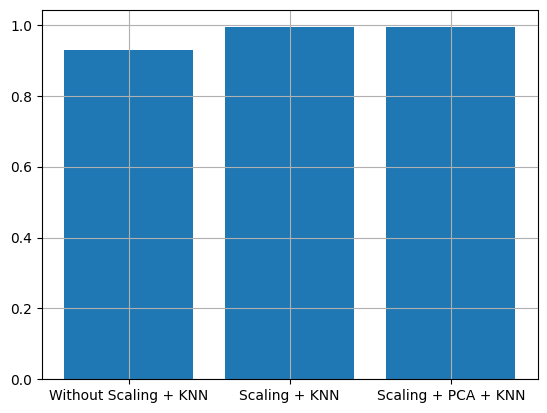

In [168]:
import matplotlib.pyplot as plt

labels = ["Without Scaling + KNN", "Scaling + KNN","Scaling + PCA + KNN"]
accuracy = [accuracy_score(y_test,y_pred),accuracy_score(y_test,y_pred_scale),accuracy_score(y_test,y_pred_pca)]

plt.bar(labels, accuracy)
plt.grid()